### Question 1 

### Question 1A 

In [1]:
import mariadb
import pandas as pd
from sqlalchemy import create_engine, text
print("libraries imported successfully")

libraries imported successfully


### Create DB

In [2]:
try:
    #Connecting to Mariadb
    conn = mariadb.connect(
        host='localhost',
        port=3306,
        user='root',
        password='YOUR_PASSWORD_HERE')
    #Creating database
    cursor = conn.cursor()
    cursor.execute("CREATE DATABASE IF NOT EXISTS CarbonEmission;")
    cursor.execute("USE CarbonEmission;")
except Exception as ex:
    print(f"Error encountered : {ex}")
    if cursor:
        cursor.close()

print("Database 'CarbonEmission' created and selected successfully.")

Database 'CarbonEmission' created and selected successfully.


In [3]:
#connecting SQLALCHEMY to MARIADB server 
username = 'root'
password = 'YOUR_PASSWORD_HERE'
server   = 'localhost'
database = 'CarbonEmission'

try:
    print("connecting to MariaDB server")
    conn_string = f"mysql+pymysql://{username}:{password}@{server}/{database}"
    dbEng = create_engine(conn_string)

except Exception as ex:
    print(f"An Error Occurred: {ex}")
    
print("SQLAlchemy connected to MariaDB successfully.")

connecting to MariaDB server
SQLAlchemy connected to MariaDB successfully.


### Extract Data

In [5]:
file = 'Q1_logistics_carbon_emissions.csv'
def extract(file_path, db_engine):
    # 2a. Load CSV
    data = pd.read_csv(file_path)
    print(f"Dataset loaded: {data.shape[0]} rows, {data.shape[1]} columns")

    # 2b. Replace dashes in column headers with underscores
    data.columns = [c.replace('-', '_') for c in data.columns]
    print("Column names cleaned:", data.columns.tolist())

    # 2c. Replace dashes with underscores in Route_Type values
    data['Route_Type'] = data['Route_Type'].str.replace('-', '_', regex=False)
    print("Route_Type values:", data['Route_Type'].unique())

    # 2d–2e. Create table 'combined' and load data
    data.to_sql('combined', con=db_engine, if_exists='replace', index=False)
    print("Table 'combined' created and loaded into CarbonEmission database.")

    return data

extracted_data = extract(file, dbEng)

Dataset loaded: 12000 rows, 11 columns
Column names cleaned: ['Transaction_ID', 'Date', 'Origin_Facility', 'Destination_City', 'Vehicle_Type', 'Route_Type', 'Distance_KM', 'Package_Weight_KG', 'Traffic_Conditions', 'Carbon_Emission_kgCO2e', 'Is_Eco_Friendly']
Route_Type values: ['Mixed Route' 'Urban Last Mile' 'Inter_City' 'Inter_District']
Table 'combined' created and loaded into CarbonEmission database.


### Transform Data 

In [7]:

# Lookup tables used by transform()
BASE_FACTORS = {
    'Cargo Bicycle':        0.00,
    'Drone Delivery':       0.02,
    'Electric Van (EV)':    0.05,
    'Motorcycle (Courier)': 0.10,
    'Diesel Van (Euro 6)':  0.20,
    'Diesel Van (Euro 4)':  0.40,
    'Heavy Truck':          1.20,
}

TRAFFIC_MULTIPLIERS = {
    'Normal':            1.00,
    'Low':               1.10,
    'High':              1.50,
    'Severe Congestion': 1.75,
}


def transform(data):
    def reclassify_route(row):
        if row['Route_Type'] != 'Mixed Route':
            return row['Route_Type']
        d = row['Distance_KM']
        if d > 100:
            return 'Inter_City'
        elif 20 <= d <= 100:
            return 'Inter_District'
        else:
            return 'Urban Last Mile'

    def calc_emission(row):
        base  = BASE_FACTORS.get(row['Vehicle_Type'], 0)
        multi = TRAFFIC_MULTIPLIERS.get(row['Traffic_Conditions'], 1)
        return round(base * row['Package_Weight_KG'] * multi * row['Distance_KM'], 4)

    data['Route_Type'] = data.apply(reclassify_route, axis=1)
    print("Route types now:", data['Route_Type'].unique())

    data['Carbon_Emission_kgCO2e'] = data.apply(calc_emission, axis=1)
    print("Emissions recalculated. Sample:")
    print(data[['Vehicle_Type','Distance_KM','Package_Weight_KG',
                'Traffic_Conditions','Carbon_Emission_kgCO2e']].head(5))
    return data

transformed_data = transform(extracted_data)

Route types now: ['Inter_District' 'Inter_City' 'Urban Last Mile']
Emissions recalculated. Sample:
          Vehicle_Type  Distance_KM  Package_Weight_KG Traffic_Conditions  \
0    Electric Van (EV)         80.4               15.6             Normal   
1  Diesel Van (Euro 6)        135.3               18.8                Low   
2       Drone Delivery          9.0               25.4             Normal   
3       Drone Delivery         11.8               13.5               High   
4          Heavy Truck        156.5             1792.6             Normal   

   Carbon_Emission_kgCO2e  
0                 62.7120  
1                559.6008  
2                  4.5720  
3                  4.7790  
4             336650.2800  


### Load Data

In [8]:

def load(data, db_engine):
    #Create one table per route type, each ordered by Vehicle_Type
    route_tables = {
    'Inter_City':     'Inter_City',
    'Inter_District': 'Inter_District',
    'Urban Last Mile': 'Urban_Last_Mile',
}

    for route_type, table_name in route_tables.items():
        subset = (
            data[data['Route_Type'] == route_type]
            .sort_values('Vehicle_Type')
            .reset_index(drop=True)
        )
        with db_engine.begin() as raw_conn:
            raw_conn.execute(text(f"DROP TABLE IF EXISTS `{table_name}`;"))
        subset.to_sql(table_name, con=db_engine, if_exists='replace', index=False)
        print(f"Table '{table_name}' saved — {len(subset)} rows.")

    # Update combined table with transformed data
    transformed_data.to_sql('combined', con=db_engine, if_exists='replace', index=False)
    print("\nAll tables saved to CarbonEmission database successfully.")

load(transformed_data, dbEng)

C:\Users\anako\AppData\Local\Temp\ipykernel_15412\2097522952.py:17: UserWarning: The provided table name 'Inter_City' is not found exactly as such in the database after writing the table, possibly due to case sensitivity issues. Consider using lower case table names.
  subset.to_sql(table_name, con=db_engine, if_exists='replace', index=False)


Table 'Inter_City' saved — 3538 rows.


C:\Users\anako\AppData\Local\Temp\ipykernel_15412\2097522952.py:17: UserWarning: The provided table name 'Inter_District' is not found exactly as such in the database after writing the table, possibly due to case sensitivity issues. Consider using lower case table names.
  subset.to_sql(table_name, con=db_engine, if_exists='replace', index=False)


Table 'Inter_District' saved — 4709 rows.


C:\Users\anako\AppData\Local\Temp\ipykernel_15412\2097522952.py:17: UserWarning: The provided table name 'Urban_Last_Mile' is not found exactly as such in the database after writing the table, possibly due to case sensitivity issues. Consider using lower case table names.
  subset.to_sql(table_name, con=db_engine, if_exists='replace', index=False)


Table 'Urban_Last_Mile' saved — 3753 rows.

All tables saved to CarbonEmission database successfully.


### Question 1B 

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from fpdf import FPDF

In [10]:
combined_df    = pd.read_sql("SELECT * FROM combined",      dbEng)
inter_city     = pd.read_sql("SELECT * FROM Inter_City",    dbEng)
inter_district = pd.read_sql("SELECT * FROM Inter_District", dbEng)
urban_lm       = pd.read_sql("SELECT * FROM Urban_Last_Mile", dbEng)

route_tables = {
    'Inter_City':      inter_city,
    'Inter_District':  inter_district,
    'Urban_Last_Mile': urban_lm,
}
print(f"combined: {len(combined_df)} rows | Inter_City: {len(inter_city)} | "
      f"Inter_District: {len(inter_district)} | Urban_Last_Mile: {len(urban_lm)}")

combined: 12000 rows | Inter_City: 3538 | Inter_District: 4709 | Urban_Last_Mile: 3753


In [11]:
results_1b_1a = {}
for route_name, df in route_tables.items():
    print(f"\n{'─'*55}")
    print(f"Route Type: {route_name}")
    print(f"{'─'*55}")
    emissions = df.groupby('Vehicle_Type')['Carbon_Emission_kgCO2e'].sum().sort_values(ascending=False)
    results_1b_1a[route_name] = emissions
    for vehicle, emission in emissions.items():
        print(f"  {vehicle:<25}: {emission:>15,.2f} kgCO2e")
    print(f"  {'TOTAL':<25}: {emissions.sum():>15,.2f} kgCO2e")


───────────────────────────────────────────────────────
Route Type: Inter_City
───────────────────────────────────────────────────────
  Heavy Truck              : 3,121,366,803.92 kgCO2e
  Diesel Van (Euro 4)      :      624,479.19 kgCO2e
  Diesel Van (Euro 6)      :      285,393.68 kgCO2e
  Electric Van (EV)        :       72,566.25 kgCO2e
  TOTAL                    : 3,122,349,243.03 kgCO2e

───────────────────────────────────────────────────────
Route Type: Inter_District
───────────────────────────────────────────────────────
  Diesel Van (Euro 4)      :      463,124.40 kgCO2e
  Diesel Van (Euro 6)      :      222,284.18 kgCO2e
  Motorcycle (Courier)     :       70,733.78 kgCO2e
  Electric Van (EV)        :       57,503.71 kgCO2e
  TOTAL                    :      813,646.07 kgCO2e

───────────────────────────────────────────────────────
Route Type: Urban_Last_Mile
───────────────────────────────────────────────────────
  Diesel Van (Euro 4)      :       12,780.79 kgCO2e
  Diesel 

In [12]:
route_distances = {name: df['Distance_KM'].sum() for name, df in route_tables.items()}
sorted_routes   = sorted(route_distances.items(), key=lambda x: x[1], reverse=True)

print(f"\n{'─'*55}")
print(f"{'RANK':<6} {'ROUTE TYPE':<20} {'TOTAL DISTANCE (KM)':>20}")
print(f"{'─'*55}")
for rank, (route_name, dist) in enumerate(sorted_routes, 1):
    print(f"{rank:<6} {route_name:<20} {dist:>20,.2f}")


───────────────────────────────────────────────────────
RANK   ROUTE TYPE            TOTAL DISTANCE (KM)
───────────────────────────────────────────────────────
1      Inter_City                     984,136.70
2      Inter_District                 217,828.80
3      Urban_Last_Mile                 32,251.40


In [13]:
eco_vehicles     = ['Cargo Bicycle', 'Drone Delivery', 'Electric Van (EV)']
non_eco_vehicles = ['Motorcycle (Courier)', 'Diesel Van (Euro 6)', 'Diesel Van (Euro 4)', 'Heavy Truck']

eco_dist     = combined_df[combined_df['Vehicle_Type'].isin(eco_vehicles)]['Distance_KM'].sum()
non_eco_dist = combined_df[combined_df['Vehicle_Type'].isin(non_eco_vehicles)]['Distance_KM'].sum()
total_dist   = eco_dist + non_eco_dist

print(f"Eco-friendly distance    : {eco_dist:>15,.2f} KM  ({eco_dist/total_dist*100:.1f}%)")
print(f"Non-eco-friendly distance: {non_eco_dist:>15,.2f} KM  ({non_eco_dist/total_dist*100:.1f}%)")
print(f"Total distance           : {total_dist:>15,.2f} KM")

Eco-friendly distance    :      164,501.50 KM  (13.3%)
Non-eco-friendly distance:    1,069,715.40 KM  (86.7%)
Total distance           :    1,234,216.90 KM


In [14]:
combined_df['Date']       = pd.to_datetime(combined_df['Date'])
combined_df['Month']      = combined_df['Date'].dt.month
combined_df['Month_Name'] = combined_df['Date'].dt.strftime('%B')

monthly_emissions = (
    combined_df
    .groupby(['Month', 'Month_Name', 'Vehicle_Type'])['Carbon_Emission_kgCO2e']
    .sum()
    .reset_index()
    .rename(columns={'Carbon_Emission_kgCO2e': 'Total_Emission'})
)

pivot_table = monthly_emissions.pivot_table(
    index=['Month', 'Month_Name'],
    columns='Vehicle_Type',
    values='Total_Emission',
    fill_value=0
)

print("Monthly Emissions Summary (kgCO2e):\n")
for (month_num, month_name), row in pivot_table.iterrows():
    print(f"{month_name} (Month {month_num}):")
    for vehicle, emission in row.items():
        if emission > 0:
            print(f"  {vehicle:<25}: {emission:>15,.2f} kgCO2e")

Monthly Emissions Summary (kgCO2e):

January (Month 1):
  Diesel Van (Euro 4)      :      101,437.73 kgCO2e
  Diesel Van (Euro 6)      :       45,455.32 kgCO2e
  Drone Delivery           :          445.18 kgCO2e
  Electric Van (EV)        :       11,125.94 kgCO2e
  Heavy Truck              :  305,128,770.96 kgCO2e
  Motorcycle (Courier)     :        6,699.71 kgCO2e
February (Month 2):
  Diesel Van (Euro 4)      :       91,652.34 kgCO2e
  Diesel Van (Euro 6)      :       42,564.05 kgCO2e
  Drone Delivery           :          349.20 kgCO2e
  Electric Van (EV)        :       10,700.82 kgCO2e
  Heavy Truck              :  252,094,335.31 kgCO2e
  Motorcycle (Courier)     :        5,415.34 kgCO2e
March (Month 3):
  Diesel Van (Euro 4)      :      101,925.17 kgCO2e
  Diesel Van (Euro 6)      :       37,265.71 kgCO2e
  Drone Delivery           :          450.58 kgCO2e
  Electric Van (EV)        :       10,893.03 kgCO2e
  Heavy Truck              :  216,193,963.14 kgCO2e
  Motorcycle (Courier) 

### Question 1C 

Route_Type              Inter_City  Inter_District  Urban Last Mile
Vehicle_Type                                                       
Cargo Bicycle                  NaN             NaN           0.0000
Diesel Van (Euro 4)   6.244792e+05     463124.3966       12780.7866
Diesel Van (Euro 6)   2.853937e+05     222284.1786        7841.6534
Drone Delivery                 NaN             NaN        4873.1701
Electric Van (EV)     7.256625e+04      57503.7140        1772.5859
Heavy Truck           3.121367e+09             NaN              NaN
Motorcycle (Courier)           NaN      70733.7803              NaN


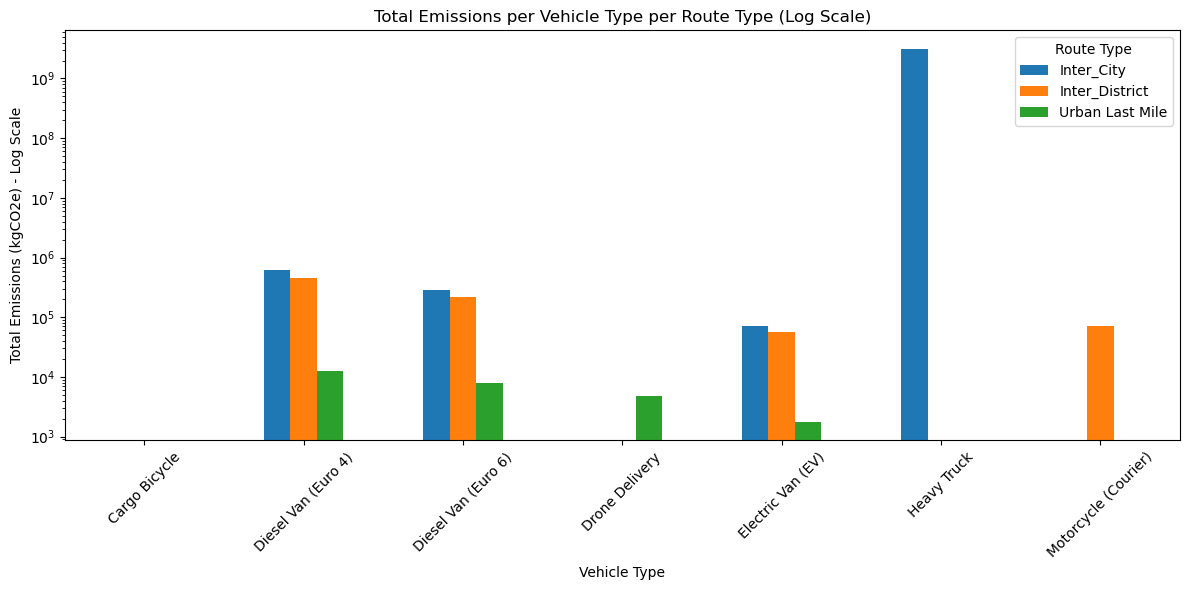

Visualization completed.


In [15]:
emission_per_vehicle = (
    combined_df
    .groupby(['Route_Type', 'Vehicle_Type'])['Carbon_Emission_kgCO2e']
    .sum()
    .reset_index()
    .rename(columns={'Carbon_Emission_kgCO2e': 'Total_Emission'})
)

pivot_df = emission_per_vehicle.pivot(
    index='Vehicle_Type',
    columns='Route_Type',
    values='Total_Emission'
)

print(pivot_df)

ax = pivot_df.plot(kind='bar', figsize=(12, 6))
ax.set_yscale('log')

plt.title("Total Emissions per Vehicle Type per Route Type (Log Scale)")
plt.xlabel("Vehicle Type")
plt.ylabel("Total Emissions (kgCO2e) - Log Scale")
plt.xticks(rotation=45)
plt.legend(title="Route Type")
plt.tight_layout()
plt.savefig('4024329_Question1C_1.png', dpi=150, bbox_inches='tight')
plt.show()
print("Visualization completed.")


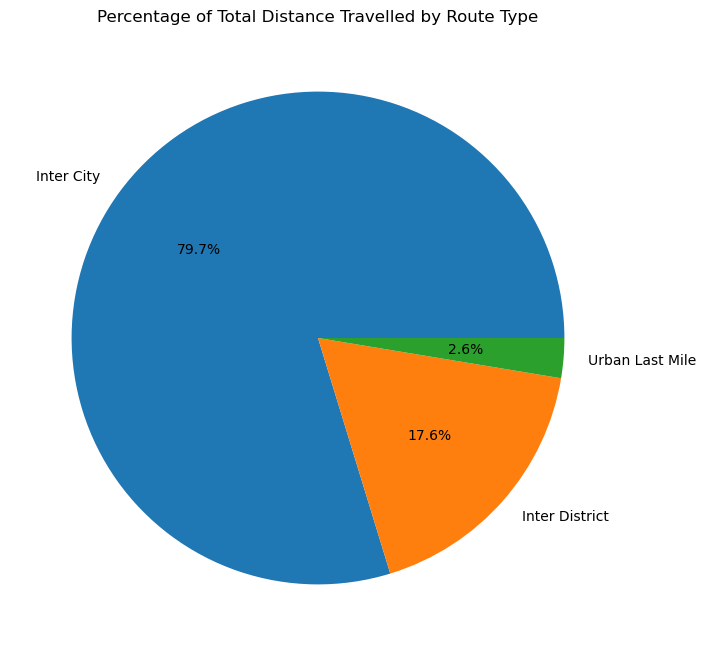

Pie chart saved.


In [16]:
route_distance = (
    combined_df
    .groupby('Route_Type')['Distance_KM']
    .sum()
    .reset_index()
    .rename(columns={'Distance_KM': 'Total_Distance'})
    .sort_values('Total_Distance', ascending=False)
)

labels = route_distance['Route_Type'].str.replace('_', ' ')

plt.figure(figsize=(8, 8))
plt.pie(
    route_distance['Total_Distance'],
    labels=labels,
    autopct='%1.1f%%'
)
plt.title("Percentage of Total Distance Travelled by Route Type")
plt.savefig('4024329_Question1C_2.png', bbox_inches='tight')
plt.show()
print("Pie chart saved.")

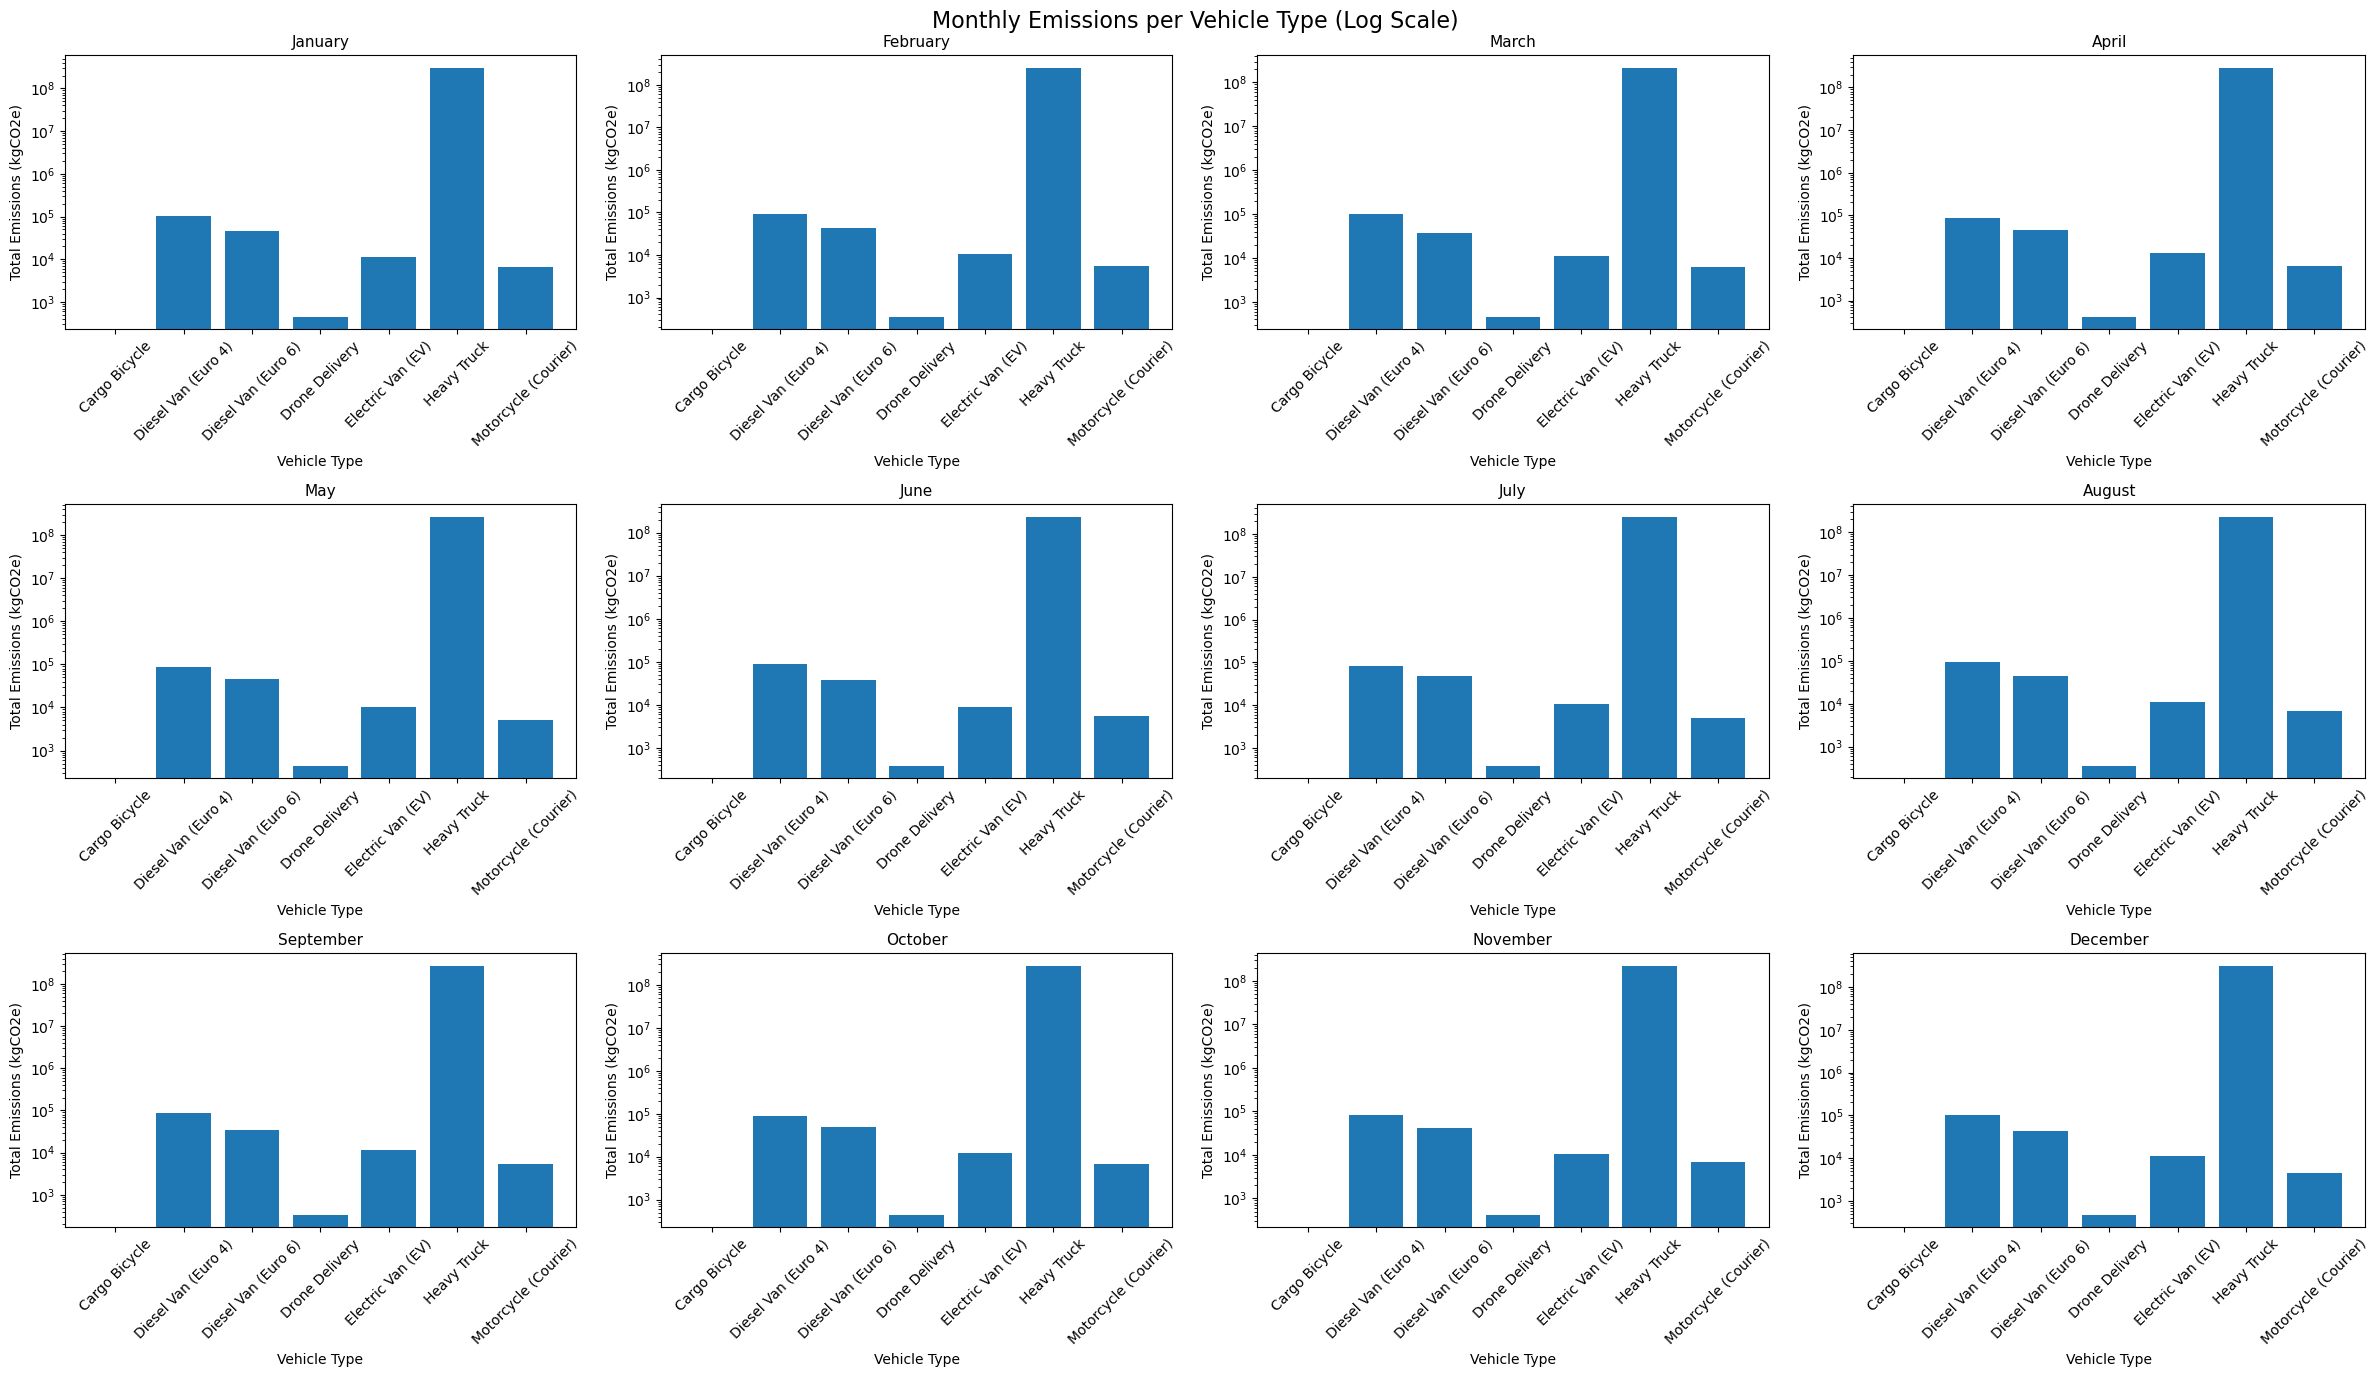

Monthly charts saved.


In [24]:
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']

fig, axes = plt.subplots(3, 4, figsize=(24, 14))
axes = axes.flatten()

for i, month in enumerate(month_order):
    month_data = monthly_emissions[monthly_emissions['Month_Name'] == month]

    axes[i].bar(month_data['Vehicle_Type'], month_data['Total_Emission'])
    axes[i].set_yscale('log')
    axes[i].set_title(month, fontsize=11)
    axes[i].set_xlabel('Vehicle Type')
    axes[i].set_ylabel('Total Emissions (kgCO2e)')
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle('Monthly Emissions per Vehicle Type (Log Scale)', fontsize=16)
plt.tight_layout()
plt.savefig('4024329_Question1C_3.png', dpi=150, bbox_inches='tight')
plt.show()
print("Monthly charts saved.")


In [25]:
pdf = FPDF()
img_paths = [
    ('4024329_Question1C_1.png', 'L', 270),
    ('4024329_Question1C_2.png', 'P', 150),
    ('4024329_Question1C_3.png', 'L', 270),
]
for img_path, orientation, width in img_paths:
    pdf.add_page(orientation=orientation)
    pdf.image(img_path, x=10, y=10, w=width)

pdf_path = '4024329_Question1C.pdf'
pdf.output(pdf_path)
print(f"Saved: {pdf_path}")

Saved: 4024329_Question1C.pdf
